<h1 align="center">Before the Shelf Runs Empty</h1>
<h3 align="center">Safety Stock and Reorder Point Under Uncertain Demand</h3>
<p align="center"><em>Math Concepts for Developers, Final Project</em></p>

## 1. Introduction and Research Questions

An online retailer of bathroom and kitchen products keeps part of its assortment in its own warehouse. When the stock of a product runs low, a purchase order goes to the supplier, who needs a fixed number of days to deliver: the **lead time**. During those days the product keeps selling. If more is sold than was on the shelf when the order was placed, the product runs out, and customers either wait or buy elsewhere.

The ordering system therefore has to pick a stock level, the **reorder point** $R$, at which the next purchase order is triggered. Picking it is a trade-off:

- too low, and the product is regularly out of stock before the supplier delivers;
- too high, and money sits on the shelf as inventory that will not be needed for weeks.

The retailer's current ordering system uses a fixed rule of thumb per product. This project asks what the rule *should* be, and how much of the reorder point exists only because demand is uncertain.

### From the warehouse to mathematics

Let $D_1, D_2, \dots$ be the number of units sold on consecutive days. The sales on a given day cannot be predicted, so each $D_i$ is a **random variable**. If the supplier needs $L$ days, the demand we must survive after placing an order is the sum

$$X = D_1 + D_2 + \dots + D_L = \sum_{i=1}^{L} D_i .$$

We do not run out during the lead time exactly when $X \le R$. The quality of a reorder point is therefore the probability

$$\alpha = P(X \le R),$$

called the **service level**. A service level of 95 % means that in 19 lead times out of 20 the stock lasts until the delivery arrives.

The reorder point splits naturally into two parts:

$$R = \underbrace{E[X]}_{\text{expected demand during the lead time}} + \underbrace{SS}_{\text{safety stock}} .$$

The first part would be enough in a world without randomness. The second part, the **safety stock** $SS$, exists only to absorb the days when demand is above average. The question of this project is: given daily sales data and a target service level, how large should $SS$ be, and what does it cost?

### Hypotheses

Three statements to test along the way, so that the end of the notebook can say which held:

1. **Safety stock grows faster than the service level.** Going from 90 % to 95 % should cost less extra stock than going from 95 % to 99 %.
2. **Different demand patterns need different safety stock, even for the same average.** The intermittent product should need more safety stock *relative to its expected demand* than the steady one.
3. **The accuracy of the normal approximation depends on the lead time and on the demand pattern.** The longer the lead time, the closer the demand during it should be to a normal distribution; a short lead time and an irregular daily demand should produce the largest errors.

### Assumptions

Every model simplifies. These are the simplifications made here, stated up front so that the results can be judged against them:

1. **Daily demands are independent of each other and share one distribution** for a given product. This is checked informally against the data in section 3, and its limits are discussed in the conclusions.
2. **The lead time is fixed and known.** We use the delivery time the supplier quotes for each product: 10, 180 and 63 days for products A, B and C.
3. **A day without a sale is a day with zero demand**, not missing data. The sales export lists only days with at least one sale.
4. **Unmet demand is lost.** A customer who finds the product out of stock buys elsewhere; the sale is not postponed.
5. **Only the reorder point is studied.** How much to order each time is a separate question and is kept fixed. The reorder point is compared with the *inventory position*, stock on hand plus units already ordered from the supplier, so that an order already on its way is not placed twice.
6. **Wholesale orders stay in the data.** One day in product C carries a single order of 40 units from a business customer, mirroring a real event. It is kept, and its effect is shown explicitly rather than removed silently.
7. **All three products are analysed over the same window: 2026-04-01 to 2026-10-31, 214 days.** This is the period in which the three real products behind the data were all regularly on sale.
8. **The data is synthetic, calibrated on real sales.** The retailer's sales export could not be published, so the notebook runs on generated series with the same statistical profile as three real products; section 2 explains how they were built.

## 2. Dataset Description and Preparation

The analysis was designed on a real export from the retailer's order database. That export could not be published, so the repository contains **synthetic daily sales with the same statistical profile**. Each day of each product was generated with two random experiments:

1. a **Bernoulli trial**: does the product sell at all today? A sale day happens with probability $q$;
2. on a sale day, the number of units is drawn from a **probability mass function**: a table $p(1), p(2), \dots$ with the probability of each quantity.

The value of $q$ and the table were set per product to match the share of sale days and the distribution of daily units of the real product. Product C additionally contains one wholesale order of 40 units on a single day (assumption 6).

The file has three columns:

| Column | Meaning |
|---|---|
| `sale_date` | calendar day, `YYYY-MM-DD` |
| `product` | `A`, `B` or `C` |
| `units` | units of that product sold on that day |

It covers 2026-04-01 to 2026-10-31, 214 days (assumption 7). As in the real export, **days without a sale are not listed**: when loading, we build the complete calendar and fill in zero for the absent days (assumption 3).

In [15]:
%matplotlib inline

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import matplotlib.dates as mdates

# One fixed colour per product, in a fixed order, so that A, B and C look the
# same on every chart in the notebook.
PRODUCT_COLORS = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}

# Supplier lead time in days, as quoted for each product.
LEAD_TIME_DAYS = {"A": 10, "B": 180, "C": 63}

DATA_PATH = "data/daily_sales.csv"
# The analysis window (assumption 7): the same 214 days for every product.
FIRST_DAY = np.datetime64("2026-04-01")
LAST_DAY = np.datetime64("2026-10-31")

# Chart defaults for the whole notebook, so that no chart has to repeat them.
plt.rcParams["figure.dpi"] = 110           # a bit sharper than the default 100
plt.rcParams["axes.spines.top"] = False    # no frame line above the plot area
plt.rcParams["axes.spines.right"] = False  # no frame line on the right side
plt.rcParams["axes.grid"] = True           # light grid lines behind the data
plt.rcParams["grid.alpha"] = 0.25          # and make them almost transparent


In [17]:
def show_table(headers, rows):
    """Render rows as a Markdown table: first column left-aligned, the rest right."""
    def cell(value):
        return str(value).replace("|", "\\|")  # a literal | would split the cell

    align = ["---:"] * len(headers)
    align[0] = ":---"
    lines = ["| " + " | ".join(cell(h) for h in headers) + " |", "| " + " | ".join(align) + " |"]
    for row in rows:
        lines.append("| " + " | ".join(cell(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))

In [18]:
def load_daily_sales(path, first_day, last_day):
    """Read the sales export and return (calendar, {product: units}).

    `calendar` holds every day from `first_day` to `last_day` inclusive and
    `units` has one entry per calendar day: the units sold on that day, with
    0 on days absent from the file.
    """
    raw = np.genfromtxt(
        path, delimiter=",", skip_header=1, encoding="utf-8",
        dtype=[("sale_date", "datetime64[D]"), ("product", "U1"), ("units", "f8")],
    )
    assert raw["sale_date"].min() >= first_day and raw["sale_date"].max() <= last_day
    calendar = np.arange(first_day, last_day + np.timedelta64(1, "D"), dtype="datetime64[D]")
    series = {}
    for product in np.unique(raw["product"]):
        rows = raw[raw["product"] == product]
        units = np.zeros(len(calendar))
        position = (rows["sale_date"] - first_day).astype(int)  # index of each sold day
        units[position] = rows["units"]
        series[product] = units
    return calendar, series


DAYS, sales = load_daily_sales(DATA_PATH, FIRST_DAY, LAST_DAY)
PRODUCTS = list(sales)  # ['A', 'B', 'C']
display(Markdown(f"**{len(DAYS)} days**, from {DAYS[0]} to {DAYS[-1]}. "))

**214 days**, from 2026-04-01 to 2026-10-31. 

In [19]:
def summarise_sales(units):
    """A few plain numbers that summarise one product's daily sales."""
    return {
        "days with sales": int(np.count_nonzero(units)),
        "total units": int(units.sum()),
        "mean units/day": round(float(units.mean()), 2),
        "max units/day": int(units.max()),
    }


columns = ["days with sales", "total units", "mean units/day", "max units/day"]
rows = []
for product in PRODUCTS:
    summary = summarise_sales(sales[product])
    rows.append([product] + [summary[c] for c in columns] + [LEAD_TIME_DAYS[product]])
show_table(["product"] + columns + ["lead time (days)"], rows)


| product | days with sales | total units | mean units/day | max units/day | lead time (days) |
| :--- | ---: | ---: | ---: | ---: | ---: |
| A | 166 | 465 | 2.17 | 9 | 10 |
| B | 73 | 126 | 0.59 | 4 | 180 |
| C | 209 | 990 | 4.63 | 46 | 63 |

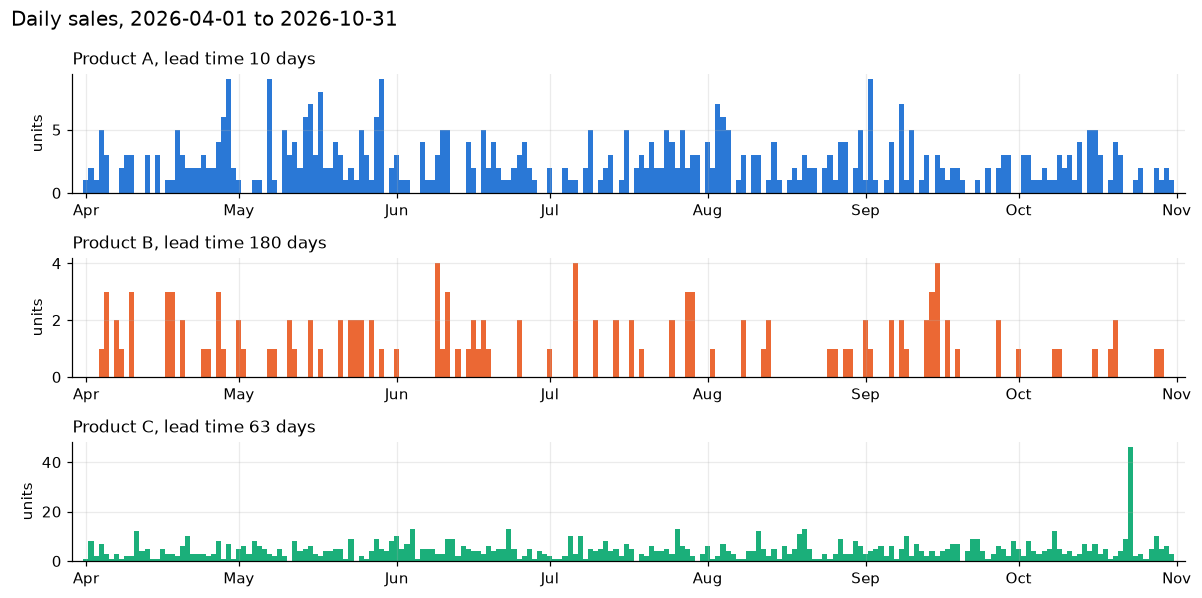

In [20]:
def plot_daily_sales(ax, product):
    """Draw one product's daily sales as bars on the given axes."""
    ax.bar(DAYS, sales[product], width=np.timedelta64(1, "D"),
           color=PRODUCT_COLORS[product], linewidth=0)
    ax.set_title(f"Product {product}, lead time {LEAD_TIME_DAYS[product]} days",
                 loc="left", fontsize=11)
    ax.set_ylabel("units")
    ax.margins(x=0.01)
    # One tick per month, labelled with the month name, under every panel.
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.tick_params(labelbottom=True)


fig, axes = plt.subplots(len(PRODUCTS), 1, figsize=(11, 5.5), sharex=True)
for ax, product in zip(axes, PRODUCTS):
    plot_daily_sales(ax, product)
fig.suptitle(f"Daily sales, {FIRST_DAY} to {LAST_DAY}", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()


### First observations

- **Product A** sells on about three days out of four, usually one to three units, with no trend. It is the textbook case of steady demand.
- **Product B** sells on about one day in three, usually one or two units at a time. Its demand is *intermittent*: the interesting question for B is not how many units, but whether anything sells at all on a given day.
- **Product C** sells on almost every day and faster than A, with larger day-to-day swings and the single 40-unit wholesale order mentioned in the assumptions.

These three shapes are exactly why the products were chosen: a steady one, an intermittent one with a long lead time, and a fast, volatile one. The next section turns the daily sales into a probability model.

## 3. Exploratory Data Analysis

The daily sales are our stand-in for the daily demand $D$ of a product. This section turns the 214 observed days into a probability model of $D$: which values it takes and how often, how far a typical day strays from the mean, and whether one day tells us anything about the next. These are the only facts about $D$ that the rest of the notebook will use.

The tool is the statistical definition of probability: if an event occurred $m$ times in $n$ trials, its probability is estimated by the relative frequency $m / n$. Each day is one trial, so

$$P(D = k) \approx \frac{\text{number of days with exactly } k \text{ units}}{214} .$$

The table of values and their relative frequencies is the **empirical probability mass function** (pmf) of the daily demand.

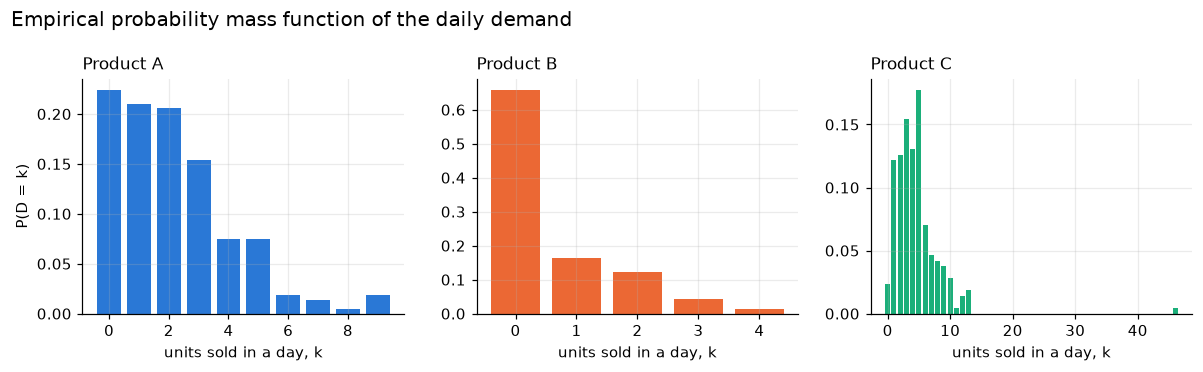

In [21]:
def empirical_pmf(units):
    """Values taken by the daily sales and the relative frequency of each one."""
    values, counts = np.unique(units, return_counts=True)
    return values.astype(int), counts / len(units)


fig, axes = plt.subplots(1, len(PRODUCTS), figsize=(11, 3.4))
for ax, product in zip(axes, PRODUCTS):
    values, probabilities = empirical_pmf(sales[product])
    ax.bar(values, probabilities, color=PRODUCT_COLORS[product], width=0.8)
    ax.set_title(f"Product {product}", loc="left", fontsize=11)
    ax.set_xlabel("units sold in a day, k")
axes[0].set_ylabel("P(D = k)")
fig.suptitle("Empirical probability mass function of the daily demand", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

### Mean and spread

For a discrete random variable with pmf $p(k)$, the **expected value** is the probability-weighted average of its values,

$$\mu_d = E[D] = \sum_k k \, p(k),$$

and the **variance** is the expected squared distance from that mean,

$$\sigma_d^2 = \mathrm{Var}(D) = E\big[(D - \mu_d)^2\big] = \sum_k (k - \mu_d)^2 \, p(k).$$

Its square root, the **standard deviation** $\sigma_d$, is in the same unit as $D$ (units per day) and measures how far a typical day lands from the mean. With the empirical pmf these two sums are exactly the mean and the standard deviation of the 214 observed values, which is how NumPy computes them; the code below checks that the two routes agree. The formulas are worth keeping in view because section 4 needs nothing else about the daily demand: the model runs on $\mu_d$ and $\sigma_d$ alone.

The ratio $\sigma_d / \mu_d$ puts the spread on the scale of the mean, so that products with very different volumes can be compared. A value near 1 or above describes a demand that is as uneven as it is large.

In [22]:
def demand_moments(units):
    """Mean, variance and standard deviation of the daily demand, from its empirical pmf."""
    values, probabilities = empirical_pmf(units)
    mean = np.sum(values * probabilities)
    variance = np.sum((values - mean) ** 2 * probabilities)
    return mean, variance, np.sqrt(variance)


rows = []
for product in PRODUCTS:
    units = sales[product]
    mean, variance, std = demand_moments(units)
    assert np.isclose(mean, units.mean()) and np.isclose(std, units.std())
    rows.append([product, f"{mean:.2f}", f"{variance:.2f}", f"{std:.2f}",
                 f"{std / mean:.2f}", f"{np.mean(units == 0):.0%}"])
show_table(["product", "mean μ", "variance σ²", "std σ", "σ / μ", "P(D = 0)"], rows)

| product | mean μ | variance σ² | std σ | σ / μ | P(D = 0) |
| :--- | ---: | ---: | ---: | ---: | ---: |
| A | 2.17 | 3.94 | 1.98 | 0.91 | 22% |
| B | 0.59 | 0.91 | 0.95 | 1.62 | 66% |
| C | 4.63 | 16.11 | 4.01 | 0.87 | 2% |

In [23]:
# Assumption 6: show what the single wholesale order does to product C's numbers.
without_order = sales["C"].copy()
without_order[np.argmax(without_order)] -= 40   # take the 40-unit order out of its day
display(Markdown(
    f"Product C without the wholesale order: mean **{without_order.mean():.2f}** instead of "
    f"{sales['C'].mean():.2f} units/day, standard deviation **{without_order.std():.2f}** "
    f"instead of {sales['C'].std():.2f}. One day out of 214 raises the spread by about "
    f"{sales['C'].std() / without_order.std() - 1:.0%}."
))

Product C without the wholesale order: mean **4.44** instead of 4.63 units/day, standard deviation **2.84** instead of 4.01. One day out of 214 raises the spread by about 41%.

### Two experiments in one day

Section 2 described each day as two random experiments: does the product sell at all, and if so, how much. The same split is a useful way to read the data. Let $S$ be the indicator "at least one unit sold today", a Bernoulli random variable with $P(S = 1) = q$. Conditioning on it,

$$E[D] = P(S = 1)\, E[D \mid S = 1] + P(S = 0)\, E[D \mid S = 0] = q \cdot E[D \mid S = 1],$$

because on a day without a sale the demand is zero. The mean daily demand is the share of sale days times the mean quantity on a sale day. For product B this decomposition is most of the story: $q$ is small and the quantity on a sale day is usually one or two units, so its variability comes from the sale-day trial, not from the quantities.

In [24]:
rows = []
for product in PRODUCTS:
    units = sales[product]
    q = np.mean(units > 0)                      # P(S = 1), share of sale days
    mean_on_sale_day = units[units > 0].mean()  # E[D | S = 1]
    rows.append([product, f"{q:.3f}", f"{mean_on_sale_day:.2f}",
                 f"{q * mean_on_sale_day:.2f}", f"{units.mean():.2f}"])
show_table(["product", "q = P(S = 1)", "E[D | S = 1]", "q · E[D | S = 1]", "E[D]"], rows)

| product | q = P(S = 1) | E[D \| S = 1] | q · E[D \| S = 1] | E[D] |
| :--- | ---: | ---: | ---: | ---: |
| A | 0.776 | 2.80 | 2.17 | 2.17 |
| B | 0.341 | 1.73 | 0.59 | 0.59 |
| C | 0.977 | 4.74 | 4.63 | 4.63 |

### Are consecutive days independent?

Assumption 1 says that the daily demands are independent: knowing yesterday's sales should not change the odds for today. For independent events $P(A \mid B) = P(A)$, so one direct check compares the probability of a sale today given a sale yesterday with the same probability given no sale yesterday. For the quantities, we compare the mean sales on the days that follow an above-average day with the mean on the days that follow a below-average day. If each pair is close, the data gives no reason to doubt the assumption.

In [25]:
rows = []
for product in PRODUCTS:
    today, yesterday = sales[product][1:], sales[product][:-1]
    rows.append([
        product,
        f"{np.mean(today > 0):.2f}",
        f"{np.mean(today[yesterday > 0] > 0):.2f}",
        f"{np.mean(today[yesterday == 0] > 0):.2f}",
        f"{today[yesterday > yesterday.mean()].mean():.2f}",
        f"{today[yesterday <= yesterday.mean()].mean():.2f}",
    ])
show_table(["product", "P(sale)", "P(sale | sale yesterday)", "P(sale | no sale yesterday)",
            "mean after an above-average day", "mean after a below-average day"], rows)

| product | P(sale) | P(sale \| sale yesterday) | P(sale \| no sale yesterday) | mean after an above-average day | mean after a below-average day |
| :--- | ---: | ---: | ---: | ---: | ---: |
| A | 0.77 | 0.78 | 0.75 | 2.16 | 2.19 |
| B | 0.34 | 0.37 | 0.33 | 0.63 | 0.57 |
| C | 0.98 | 0.98 | 1.00 | 4.78 | 4.53 |

### What the data tells us

- **Product A** takes values from 0 to 9 units with a mean of 2.17 and a standard deviation of 1.98: the spread is almost as large as the mean ($\sigma / \mu \approx 0.9$).
- **Product B** is zero on two days out of three. Its mean is 0.59 units per day and its standard deviation 0.95, so $\sigma / \mu \approx 1.6$, by far the most uneven of the three, as hypothesis 2 expects of an intermittent product.
- **Product C** has a mean of 4.63 and a standard deviation of 4.01, but more than a quarter of that spread comes from a single day. Without the wholesale order its $\sigma / \mu$ would be below A's. The order stays in the data (assumption 6); section 7 returns to what it does to the safety stock.
- **Independence.** For every product the two conditional probabilities differ by at most 0.04, and the two conditional means by less than a tenth of the mean, well within what 214 days of chance can produce. The one exception, product C after a day without a sale, rests on five days and says nothing. Nothing here argues against assumption 1. With synthetic data this check mostly confirms how the series were built; on a real export it would be the step deserving the most attention, because weekday and seasonal patterns are exactly what it would catch.

Section 4 takes $\mu_d$ and $\sigma_d$ for each product and asks what happens when $L$ such days are added together.

## 4. Mathematical Background

Section 3 reduced each product to two numbers, the mean $\mu_d$ and the standard deviation $\sigma_d$ of its daily demand, and found no reason to doubt that the days are independent. This section builds the model on top of them, in four steps:

1. what the mean and the spread of the demand during the lead time are;
2. what shape its distribution has;
3. how a target service level turns into a reorder point;
4. which service level is worth paying for.

### Demand during the lead time

The demand during a lead time of $L$ days is the sum $X = D_1 + D_2 + \dots + D_L$ of $L$ daily demands. The expected value of a sum is the sum of the expected values, whatever the dependence between the terms, so

$$\mu_X = E[X] = \sum_{i=1}^{L} E[D_i] = L\,\mu_d .$$

For the variance we need assumption 1. For two random variables $A$ and $B$,

$$\mathrm{Var}(A + B) = E\big[(A - \mu_A + B - \mu_B)^2\big] = \mathrm{Var}(A) + \mathrm{Var}(B) + 2\,E\big[(A - \mu_A)(B - \mu_B)\big],$$

and the last term vanishes when $A$ and $B$ are independent, because then the expected value of the product is the product of the expected values, $E[(A - \mu_A)(B - \mu_B)] = E[A - \mu_A]\,E[B - \mu_B] = 0$. Applied $L - 1$ times to independent days with the same distribution:

$$\sigma_X^2 = \mathrm{Var}(X) = L\,\sigma_d^2, \qquad \sigma_X = \sigma_d \sqrt{L} .$$

The expected demand grows in proportion to the lead time, but its uncertainty grows only with the square root of it. The relative uncertainty $\sigma_X / \mu_X = (\sigma_d / \mu_d) / \sqrt{L}$ therefore shrinks as the lead time gets longer: a long lead time means a lot of demand, but a comparatively predictable one.

In [26]:
def lead_time_demand_moments(units, lead_time):
    """Mean and standard deviation of the demand summed over `lead_time` independent days."""
    mean_d, _, std_d = demand_moments(units)
    return lead_time * mean_d, std_d * np.sqrt(lead_time)


rows = []
for product in PRODUCTS:
    units, lead_time = sales[product], LEAD_TIME_DAYS[product]
    mean_d, _, std_d = demand_moments(units)
    mean_x, std_x = lead_time_demand_moments(units, lead_time)
    rows.append([product, lead_time, f"{mean_d:.2f}", f"{std_d:.2f}",
                 f"{mean_x:.1f}", f"{std_x:.1f}", f"{std_x / mean_x:.2f}"])
show_table(["product", "L (days)", "μ_d", "σ_d", "μ_X = L·μ_d", "σ_X = σ_d·√L", "σ_X / μ_X"], rows)

| product | L (days) | μ_d | σ_d | μ_X = L·μ_d | σ_X = σ_d·√L | σ_X / μ_X |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| A | 10 | 2.17 | 1.98 | 21.7 | 6.3 | 0.29 |
| B | 180 | 0.59 | 0.95 | 106.0 | 12.8 | 0.12 |
| C | 63 | 4.63 | 4.01 | 291.4 | 31.9 | 0.11 |

### The shape of the sum

Knowing $\mu_X$ and $\sigma_X$ is not yet enough to find $P(X \le R)$; for that we need the distribution of $X$. The **central limit theorem** says that the sum of many independent random variables with the same distribution is approximately **normally distributed**, whatever the shape of the summands, with the mean and the variance derived above. The normal distribution with mean $\mu$ and standard deviation $\sigma$ has the probability density function

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}}\, e^{-\frac{(x - \mu)^2}{2\sigma^2}} .$$

This is what makes the model practical: the three daily pmfs of section 3 look nothing alike, yet the lead-time demand of every product should be described by the same bell-shaped curve, pinned down by two numbers.

The theorem speaks of "many" days, and our lead times range from 10 to 180. To see how good the approximation is, we draw $L$ days at random from the observed ones, add them up, and repeat this 20 000 times. The relative frequencies of the sums (again the statistical definition of probability) are compared with the normal density.

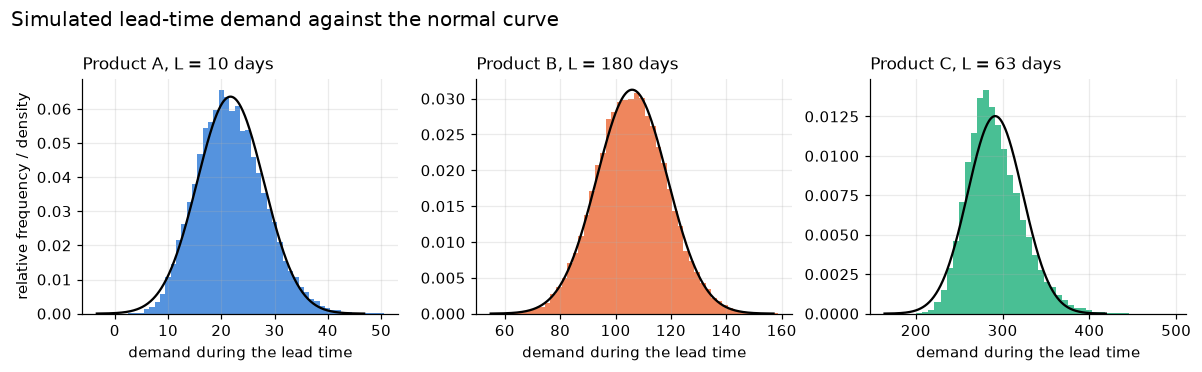

In [27]:
def normal_pdf(x, mean, std):
    """Probability density function of the normal distribution."""
    return np.exp(-((x - mean) ** 2) / (2 * std ** 2)) / (std * np.sqrt(2 * np.pi))


def simulate_lead_time_demand(units, lead_time, n_samples, rng):
    """Sum `lead_time` randomly chosen observed days, `n_samples` times."""
    return rng.choice(units, size=(n_samples, lead_time)).sum(axis=1)


rng = np.random.default_rng(2026)

fig, axes = plt.subplots(1, len(PRODUCTS), figsize=(11, 3.4))
for ax, product in zip(axes, PRODUCTS):
    units, lead_time = sales[product], LEAD_TIME_DAYS[product]
    sums = simulate_lead_time_demand(units, lead_time, 20_000, rng)
    mean_x, std_x = lead_time_demand_moments(units, lead_time)

    bin_width = max(1, round((sums.max() - sums.min()) / 40))
    bins = np.arange(sums.min() - 0.5, sums.max() + bin_width, bin_width)
    ax.hist(sums, bins=bins, density=True, color=PRODUCT_COLORS[product], alpha=0.8)
    x = np.linspace(mean_x - 4 * std_x, mean_x + 4 * std_x, 400)
    ax.plot(x, normal_pdf(x, mean_x, std_x), color="black", linewidth=1.5)
    ax.set_title(f"Product {product}, L = {lead_time} days", loc="left", fontsize=11)
    ax.set_xlabel("demand during the lead time")
axes[0].set_ylabel("relative frequency / density")
fig.suptitle("Simulated lead-time demand against the normal curve", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

For product B, with 180 days to add up, the normal curve follows the simulated frequencies closely. Product A, with only 10 days, is already close, with a slightly heavier right tail inherited from its skewed daily pmf. The surprise is product C: although 63 days are summed, the simulated distribution is narrower and more peaked than the curve and has a long right tail.

The cause is the wholesale order. About one simulated lead time in four contains that day ($1 - (213/214)^{63} \approx 0.26$), and those windows carry 40 extra units, so the lead-time demand is really a mixture of two bells about 40 units apart. The single normal curve, whose $\sigma_X$ was inflated by the same day, is too wide for the first bell and too low for the second. The central limit theorem is not wrong, but 63 days are too few for a one-in-214 event to average out. This is evidence for the second half of hypothesis 3, that the demand pattern matters and not only the lead time, and it is the effect assumption 6 promised to show; section 6 measures what it does to the service level.

### From a service level to a reorder point

With $X$ approximately normal, the service level of a reorder point $R$ is an **area under the density curve**:

$$\alpha = P(X \le R) = \int_{-\infty}^{R} f(x)\,dx .$$

The substitution $z = (x - \mu_X) / \sigma_X$ turns any normal distribution into the **standard normal** one, with mean 0 and standard deviation 1. The value

$$z = \frac{R - \mu_X}{\sigma_X}$$

is the **z-score** of the reorder point: how many standard deviations it lies above the expected demand. The service level then depends on $z$ alone,

$$\alpha = \Phi(z) = \int_{-\infty}^{z} \varphi(t)\,dt, \qquad \varphi(t) = \frac{1}{\sqrt{2\pi}}\, e^{-t^2/2},$$

where $\Phi$ is the cumulative distribution function of the standard normal. $\varphi$ has no elementary antiderivative, so $\Phi$ cannot be written as a closed formula; section 5 computes it by numerical integration with the trapezoidal rule.

Reading the relation backwards gives the reorder point. For a target service level $\alpha$, let $z_\alpha$ be the value with $\Phi(z_\alpha) = \alpha$. Then

$$R = \mu_X + z_\alpha\,\sigma_X, \qquad SS = R - \mu_X = z_\alpha\,\sigma_X = z_\alpha\,\sigma_d\sqrt{L} .$$

Three things can be read off this formula before any number is computed:

- the safety stock grows with $\sqrt{L}$, not with $L$;
- it is proportional to $\sigma_d$, so of two products with the same mean the more uneven one needs more (hypothesis 2);
- it is proportional to $z_\alpha$, and because the bell curve gets thin in its tail, each further step towards $\alpha = 1$ needs a larger step in $z$ (hypothesis 1).

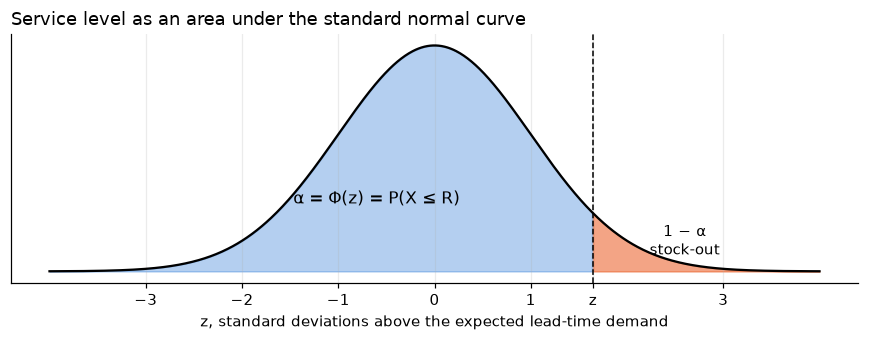

In [28]:
z_example = 1.645   # any positive z serves for the picture; this one is computed in section 5
t = np.linspace(-4, 4, 800)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(t, normal_pdf(t, 0, 1), color="black", linewidth=1.5)
ax.fill_between(t, normal_pdf(t, 0, 1), where=t <= z_example, color=PRODUCT_COLORS["A"], alpha=0.35)
ax.fill_between(t, normal_pdf(t, 0, 1), where=t > z_example, color=PRODUCT_COLORS["B"], alpha=0.6)
ax.axvline(z_example, color="black", linewidth=1, linestyle="--")
ax.text(-0.6, 0.12, "α = Φ(z) = P(X ≤ R)", ha="center", fontsize=11)
ax.text(2.6, 0.03, "1 − α\nstock-out", ha="center", fontsize=10)
ax.set_xticks([-3, -2, -1, 0, 1, z_example, 3], ["−3", "−2", "−1", "0", "1", "z", "3"])
ax.set_yticks([])
ax.set_xlabel("z, standard deviations above the expected lead-time demand")
ax.set_title("Service level as an area under the standard normal curve", loc="left", fontsize=12)
fig.tight_layout()
plt.show()

### Which service level to aim for

A service level is a choice, and the formula above only says what it costs in stock. To see which choice is reasonable, we give the two sides of the trade-off a price per replenishment cycle:

- $h$, the cost of holding one unit of safety stock through the cycle (capital tied up, warehouse space);
- $p$, the cost of one unit of demand that could not be served (the lost margin, at least).

If $X$ turns out larger than $R$, the shortage is $X - R$, otherwise it is zero. The expected cost of a reorder point $R$ is then

$$C(R) = h\,(R - \mu_X) + p \int_{R}^{\infty} (x - R)\, f(x)\,dx .$$

To find the minimum we differentiate. Splitting the integral into $\int_R^\infty x f(x)\,dx - R \int_R^\infty f(x)\,dx$ and using the fundamental theorem of calculus, the derivative of $\int_R^\infty g(x)\,dx$ with respect to $R$ is $-g(R)$, together with the product rule:

$$\frac{d}{dR} \int_{R}^{\infty} (x - R)\, f(x)\,dx = -R f(R) - \big(1 - F(R)\big) + R f(R) = -\big(1 - F(R)\big),$$

where $F(R) = P(X \le R)$ is the cumulative distribution function. Hence

$$C'(R) = h - p\,\big(1 - F(R)\big), \qquad C'(R^*) = 0 \iff F(R^*) = \frac{p}{p + h} .$$

The second derivative $C''(R) = p\,f(R) > 0$ confirms a minimum. The optimal service level is therefore

$$\alpha^* = \frac{p}{p + h},$$

the **critical ratio**: it depends only on how expensive a lost sale is compared with holding a unit. A margin of 30 € against a holding cost of 3 € per cycle gives $\alpha^* \approx 0.91$; the same margin against 1 € gives 0.97. The retailer's real costs are not part of this project, so section 5 treats the ratio $p / h$ as a parameter and shows how $R^*$ moves with it. It also minimises $C(R)$ numerically, by gradient descent on the derivative above, as a check that the formula and the numbers agree.

### The model in one place

| Quantity | Formula | Comes from |
|---|---|---|
| expected lead-time demand | $\mu_X = L\,\mu_d$ | linearity of the expected value |
| its standard deviation | $\sigma_X = \sigma_d\sqrt{L}$ | variances of independent terms add |
| its distribution | $X \approx \mathcal{N}(\mu_X, \sigma_X^2)$ | central limit theorem |
| service level of $R$ | $\alpha = \Phi\!\left(\dfrac{R - \mu_X}{\sigma_X}\right)$ | area under the standard normal density |
| reorder point for a target $\alpha$ | $R = \mu_X + z_\alpha\,\sigma_X$ | inverting $\Phi$ |
| safety stock | $SS = z_\alpha\,\sigma_d\sqrt{L}$ | $R - \mu_X$ |
| cost-optimal service level | $\alpha^* = p / (p + h)$ | $C'(R) = 0$ |

Everything that follows is arithmetic on these seven lines.